In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression

# Load dataset
df = pd.read_csv("../data/archive/creditcard.csv")

# Remove duplicates
df = df.drop_duplicates().copy()

# Separate features and target
X = df.drop("Class", axis=1)
y = df["Class"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale Time and Amount
scaler = StandardScaler()

X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

# Apply SMOTE only to training data
smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train, y_train
)

print("Data preparation completed!")
print("Training data:", X_train_resampled.shape)
print("Testing data:", X_test.shape)

Data preparation completed!
Training data: (453204, 30)
Testing data: (56746, 30)


In [3]:
# Initialize Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [4]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)

# Predict fraud or genuine transactions
y_pred = logistic_model.predict(X_test)

# Get fraud prediction probabilities
y_pred_proba = logistic_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nROC-AUC:", roc_auc_score(y_test, y_pred_proba))
print("PR-AUC:", average_precision_score(y_test, y_pred_proba))

Accuracy: 0.9736721531033025

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746


Confusion Matrix:
[[55169  1482]
 [   12    83]]

ROC-AUC: 0.9618957810936585
PR-AUC: 0.6768816018011278


## Logistic Regression - Results

- Accuracy: 97.37%
- Fraud Precision: 5%
- Fraud Recall: 87%
- Fraud F1-score: 0.10
- ROC-AUC: 0.9619
- PR-AUC: 0.6769

### Observations
1. The model detected 83 out of 95 fraudulent transactions.
2. It missed 12 fraudulent transactions.
3. It incorrectly flagged 1,482 genuine transactions.
4. Fraud recall is good, but fraud precision is very low.
5. The model generates too many false positives.

Conclusion: Logistic Regression provides a useful baseline, but its fraud predictions need improvement.

In [5]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(
    X_train_resampled,
    y_train_resampled
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [6]:
# Predict fraud or genuine transactions
rf_y_pred = random_forest_model.predict(X_test)

# Get prediction probabilities
rf_y_pred_proba = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("Random Forest Results")
print("---------------------")

print("Accuracy:", accuracy_score(y_test, rf_y_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_y_pred))

print("\nROC-AUC:", roc_auc_score(y_test, rf_y_pred_proba))
print("PR-AUC:", average_precision_score(y_test, rf_y_pred_proba))

Random Forest Results
---------------------
Accuracy: 0.9991012582384662

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.72      0.77      0.74        95

    accuracy                           1.00     56746
   macro avg       0.86      0.88      0.87     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix:
[[56622    29]
 [   22    73]]

ROC-AUC: 0.978929902291872
PR-AUC: 0.7954005483458295


## Model Comparison

Two machine learning algorithms were trained and evaluated:

1. Logistic Regression
2. Random Forest Classifier

### Observations

- Random Forest achieved 99.91% accuracy.
- Random Forest achieved 72% fraud precision.
- Random Forest detected 73 out of 95 fraudulent transactions.
- Logistic Regression detected 83 out of 95 fraudulent transactions.
- Random Forest reduced false positives from 1,482 to 29.
- Random Forest achieved a better F1-score and PR-AUC.

### Conclusion

Random Forest performed better overall, providing a stronger balance between fraud precision and recall.

However, Logistic Regression achieved higher fraud recall. Further experimentation with model parameters and classification thresholds may improve the results.

In [7]:
print("Random Forest model:", "random_forest_model" in globals())
print("Testing features:", "X_test" in globals())
print("Testing labels:", "y_test" in globals())

Random Forest model: True
Testing features: True
Testing labels: True


Top 10 Important Features:
V14    0.205119
V10    0.126519
V12    0.101861
V17    0.095466
V4     0.090846
V11    0.056301
V3     0.055262
V16    0.053350
V2     0.037811
V9     0.026253
dtype: float64


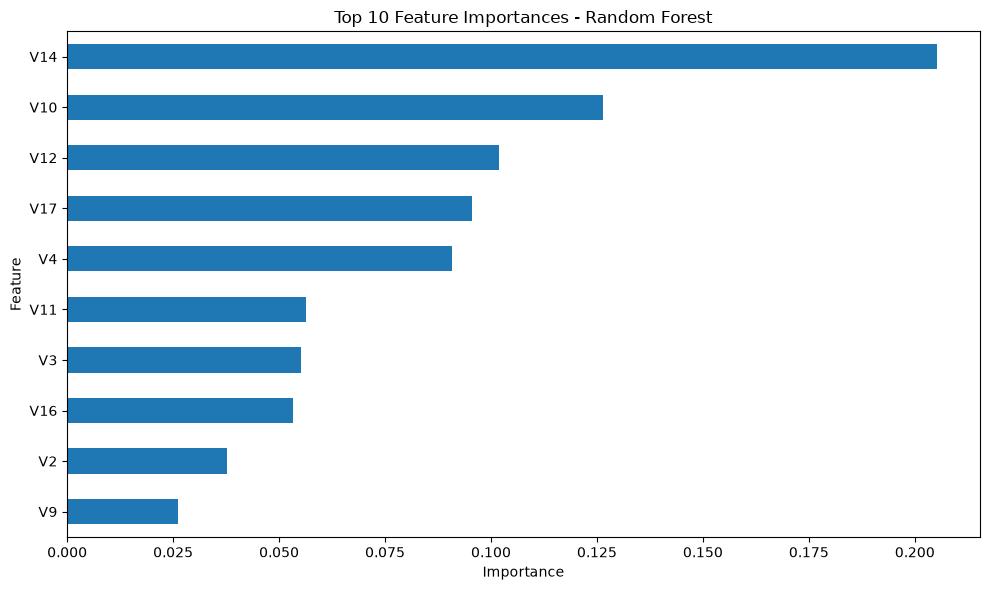

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X_train_resampled.columns
).sort_values(ascending=False)

print("Top 10 Important Features:")
print(feature_importance.head(10))

plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Feature Importance Analysis

Feature importance analysis was performed using the trained Random Forest model.

Key observations:

1. V14 is the most important feature.
2. V10, V12, V17 and V4 are also highly influential.
3. The model relies heavily on PCA-transformed features.
4. Time and Amount are not among the top 10 important features.

This analysis helps identify which features contribute most to the model's predictions. However, feature importance does not establish a causal relationship with fraudulent transactions.

In [9]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier

# Split the original training data into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Apply SMOTE only to the new training portion
smote = SMOTE(random_state=42)

X_fit_resampled, y_fit_resampled = smote.fit_resample(
    X_fit,
    y_fit
)

print("Training data:", X_fit_resampled.shape)
print("Validation data:", X_val.shape)

print("\nValidation class distribution:")
print(y_val.value_counts())

Training data: (362564, 30)
Validation data: (45396, 30)

Validation class distribution:
Class
0    45320
1       76
Name: count, dtype: int64


In [10]:
threshold_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

threshold_model.fit(X_fit_resampled, y_fit_resampled)

print("Threshold tuning model trained successfully!")

Threshold tuning model trained successfully!


In [11]:
# Predict fraud probabilities on validation data
y_val_probabilities = threshold_model.predict_proba(X_val)[:, 1]

print("First 10 fraud probabilities:")
print(y_val_probabilities[:10])

First 10 fraud probabilities:
[0.00344413 0.00542816 0.00531502 0.00765484 0.0042926  0.00193351
 0.00545303 0.00313074 0.00088636 0.06142733]


In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

results = []

for threshold in thresholds:

    y_val_pred = (y_val_probabilities >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

   Threshold  Precision  Recall  F1 Score
0        0.2     0.1482  0.8816    0.2538
1        0.3     0.3384  0.8816    0.4891
2        0.4     0.6000  0.8684    0.7097
3        0.5     0.7471  0.8553    0.7975
4        0.6     0.8442  0.8553    0.8497


In [13]:
from sklearn.metrics import confusion_matrix, classification_report

best_threshold = 0.6

y_val_pred_best = (
    y_val_probabilities >= best_threshold
).astype(int)

cm = confusion_matrix(y_val, y_val_pred_best)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_best))

Confusion Matrix:
[[45308    12]
 [   11    65]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     45320
           1       0.84      0.86      0.85        76

    accuracy                           1.00     45396
   macro avg       0.92      0.93      0.92     45396
weighted avg       1.00      1.00      1.00     45396



## Classification Threshold Tuning

Threshold tuning was performed using a separate validation dataset.

Five thresholds (0.2, 0.3, 0.4, 0.5 and 0.6) were evaluated.

### Best Threshold: 0.6

The threshold of 0.6 achieved the highest F1 score among the tested thresholds.

### Validation Results

- Precision: 84.42%
- Recall: 85.53%
- F1 Score: 84.97%
- True Positives: 65
- True Negatives: 45,308
- False Positives: 12
- False Negatives: 11

The selected threshold improves the balance between precision and recall compared with the default threshold.

Note: This threshold was selected using validation data. Final performance must be evaluated on the untouched test dataset.

In [14]:
# Train the final Random Forest model

final_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train_resampled, y_train_resampled)

print("Final Random Forest model trained successfully!")

Final Random Forest model trained successfully!


In [15]:
# Predict fraud probabilities on the test dataset
y_test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply our selected threshold
best_threshold = 0.6

y_test_pred = (
    y_test_probabilities >= best_threshold
).astype(int)

print("Final predictions generated successfully!")

Final predictions generated successfully!


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

print("FINAL RANDOM FOREST MODEL RESULTS")
print("-----------------------------------")

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 Score:", f1_score(y_test, y_test_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_test_probabilities))
print("PR-AUC:", average_precision_score(y_test, y_test_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

FINAL RANDOM FOREST MODEL RESULTS
-----------------------------------
Accuracy: 0.9992246149508336
Precision: 0.7684210526315789
Recall: 0.7684210526315789
F1 Score: 0.7684210526315789
ROC-AUC: 0.978929902291872
PR-AUC: 0.7954005483458295

Confusion Matrix:
[[56629    22]
 [   22    73]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.77      0.77      0.77        95

    accuracy                           1.00     56746
   macro avg       0.88      0.88      0.88     56746
weighted avg       1.00      1.00      1.00     56746



## Final Random Forest Model Evaluation

The final Random Forest model was trained using the complete SMOTE-balanced training dataset and evaluated on the untouched test dataset.

### Model Configuration
- Algorithm: Random Forest Classifier
- Number of estimators: 100
- Maximum depth: 12
- Minimum samples per leaf: 2
- Classification threshold: 0.6

### Final Test Results

| Metric | Score |
|---|---:|
| Accuracy | 99.92% |
| Precision | 76.84% |
| Recall | 76.84% |
| F1 Score | 76.84% |
| ROC-AUC | 0.9789 |
| PR-AUC | 0.7954 |

### Confusion Matrix Results
- True Negatives: 56,629
- False Positives: 22
- False Negatives: 22
- True Positives: 73

### Conclusion

The final Random Forest model correctly identified 73 out of 95 fraudulent transactions while incorrectly flagging 22 genuine transactions.

The model achieved a ROC-AUC score of 0.9789 and a PR-AUC score of 0.7954.

The results demonstrate that Random Forest can effectively distinguish fraudulent and genuine transactions in this highly imbalanced dataset. However, 22 fraudulent transactions were still missed, indicating opportunities for further improvement.